In [16]:
import numpy as np
from copy import deepcopy
from collections import deque
import matplotlib.pyplot as plt
import networkx as nx

In [17]:
graph_1 ={ # Планарный
       0: [1, 2, 3],
       1: [0, 2, 3],
       2: [0, 1, 3],
       3: [0, 1, 2]
}


graph_2 = { # Планарный
       0: [1, 4, 5],
       1: [0, 2, 6],
       2: [1, 3, 7],
       3: [2, 4, 8],
       4: [0, 3, 9],
       5: [0, 10, 14],
       6: [1, 10, 11],
       7: [2, 11, 12],
       8: [3, 12, 13],
       9: [4, 13, 14],
       10: [5, 6, 15],
       11: [6, 7, 16],
       12: [7, 8, 17],
       13: [8, 9, 18],
       14: [5, 9, 19],
       15: [10, 16, 19],
       16: [11, 15, 17],
       17: [12, 16, 18],
       18: [13, 17, 19],
       19: [14, 15, 18]
}

graph_3 = {  # Планарный
       0: [1, 2, 3, 4, 5],
       1: [0, 2, 5, 6],
       2: [0, 1, 3, 6, 7],
       3: [0, 2, 4, 7],
       4: [0, 3, 5, 6, 7],
       5: [0, 1, 4, 6],
       6: [1, 2, 4, 5, 7],
       7: [2, 3, 4, 6]
 }

graph_4 = { # Не ланарный
       0: [3, 4, 5],
       1: [3, 4, 5],
       2: [3, 4, 5],
       3: [0, 1, 2],
       4: [0, 1, 2],
       5: [0, 1, 2]
 }

graph_5 = { # Не планарный
       0: [1, 2, 3, 4],
       1: [0, 2, 3, 4],
       2: [0, 1, 3, 4],
       3: [0, 1, 2, 4],
       4: [0, 1, 2, 3]
}

graph_6 = {# Не планарный
       0: [1, 2, 3, 4],
       1: [0, 2, 3, 4, 5],
       2: [0, 1, 3, 4, 6],
       3: [0, 1, 2, 4, 7],
       4: [0, 1, 2, 3, 5, 7],
       5: [1, 4, 6],
       6: [2, 5, 7],
       7: [3, 4, 6]
 }

graph_7 = { # Не планарный
       0: [1, 2, 3, 6, 7, 8, 10, 11, 13],
       1: [0, 3, 4, 5, 6, 7, 9, 13, 14],
       2: [0, 4, 6, 7, 10, 13, 14],
       3: [0, 1, 6, 7, 8, 9, 11, 12, 13],
       4: [1, 2, 5, 6, 7, 8, 9, 11, 12, 13],
       5: [1, 4, 7, 9, 10, 11, 12],
       6: [0, 1, 2, 3, 4, 8, 9, 11, 12, 13, 14],
       7: [0, 1, 2, 3, 4, 5, 8, 10, 11, 12, 13, 14],
       8: [0, 3, 4, 6, 7, 9, 10, 11, 12],
       9: [1, 3, 4, 5, 6, 8, 10, 11, 14],
       10: [0, 2, 5, 7, 8, 9, 13, 14],
       11: [0, 3, 4, 5, 6, 7, 8, 9, 12, 13, 14],
       12: [3, 4, 5, 6, 7, 8, 11, 13, 14],
       13: [0, 1, 2, 3, 4, 6, 7, 10, 11, 12, 14],
       14: [1, 2, 6, 7, 9, 10, 11, 12, 13]
 }


graph_8 = {
       0: [1, 6],
       1: [0, 2, 7],
       2: [1, 3, 6, 7],
       3: [2, 4, 8, 9],
       4: [3, 5, 8],
       5: [4, 6, 9],
       6: [0, 2, 5, 9],
       7: [1, 2, 8],
       8: [3, 4, 7],
       9: [3, 5, 6]
 }

In [18]:
def edge_key(u, v):
    """
    Превращает ребро (u, v) в (u, v) и (v, u) в (u, v)
    """
    return (u, v) if u <= v else (v, u)

def find_cycle(graph):
    for s in sorted(graph):
        on_path = {s}
        path = [s]
        stack = [(s, None, iter(graph[s]))]

        while stack:
            v, parent, neighbors = stack[-1]
            w = next(neighbors, None)

            if w is None:
                stack.pop()
                path.pop()
                on_path.discard(v)

            elif w == parent:
                pass

            elif w == s:
                if path[1] < path[-1]:
                    return path + [s]

            elif w not in on_path and w > s:
                on_path.add(w)
                path.append(w)
                stack.append((w, v, iter(graph[w])))

def make_faces(cycle):
    """Функция для ицилизация граней (внутреняя и внешняя)"""
    return [cycle[:-1], cycle[:-1][::-1]]

def attach_faces(segments, faces):
    """Для каждого сегмента формирует множество допустимых граней"""
    for s in segments:
        need = s['contacts']
        s['faces'] = [k for k, face in enumerate(faces) if need <= set(face)]
    

def find_segments(graph, placed_v, placed_e):
    """Функция для нахождения сегментов"""
    segments = []

    for u in sorted(placed_v):
        for v in graph[u]:
            if u < v and v in placed_v and edge_key(u, v) not in placed_e:
                segments.append({'contacts': {u, v},
                                 'inner': set(),
                                 'edges': {edge_key(u, v)}})

    visited = set()
    for start in graph:
        if start in placed_v or start in visited:
            continue

        inner, contacts, edges = {start}, set(), set()
        visited.add(start)
        queue = deque([start])

        while queue:
            x = queue.popleft()
            for y in graph[x]:
                edges.add(edge_key(x, y))
                if y in placed_v:
                    contacts.add(y)
                elif y not in inner:
                    inner.add(y)
                    visited.add(y)
                    queue.append(y)

        segments.append({'contacts': contacts,
                         'inner': inner,
                         'edges': edges})

    return segments

def choose_placement(segments):
    """Ищет лучший сегмент для вставки по минимальной мощности множества допустимых граней.
     В алгоритме Демукрона, если есть сегмент с 1 допустимой гранью, то его берут в приоритет. """
    best = None
    for s in segments:
        if not s['faces']:
            return False
        if best is None or len(s['faces']) < len(best['faces']):
            best = s
    return best


def find_chain(segment):
    """Поиск альфа цепи в сегменте. Берем контактную вершину и ищем вторую контактную вершину через dfs"""
    adj = {v: [] for v in segment['contacts'] | segment['inner']}
    for u, v in segment['edges']:
        adj[u].append(v)
        adj[v].append(u)

    contacts = segment['contacts']

    start = min(contacts)
    parent = {start: None}
    queue = deque([start])
    while queue:
        x = queue.popleft()
        for y in adj[x]:
            if y in parent:
                continue
            parent[y] = x
            if y in contacts:
                chain = [y]
                while parent[chain[-1]] is not None:
                    chain.append(parent[chain[-1]])
                return chain[::-1]
            queue.append(y)

def split_face(face, chain):
    """Делим существующую грань"""
    u, v = chain[0], chain[-1]
    mid = chain[1:-1]

    i, j = face.index(u), face.index(v)
    if i < j:
        arc_uv = face[i:j + 1]
        arc_vu = face[j:] + face[:i + 1]
    else:
        arc_uv = face[i:] + face[:j + 1]
        arc_vu = face[j:i + 1]
    
    f1 = arc_uv + mid[::-1]
    f2 = arc_vu + mid
    return [f1, f2]

def gamma_embedding(graph):
    """Гамма-алгоритм: возвращает грани планарной укладки (список циклов)
    или None, если граф не планарен."""
    graph = deepcopy(graph)
    cycle = find_cycle(graph)
    if cycle is None:                     # нет ни одного цикла
        return None

    placed_v = set(cycle)
    placed_e = {edge_key(cycle[i], cycle[i + 1]) for i in range(len(cycle) - 1)}
    faces = make_faces(cycle)

    while True:
        segments = find_segments(graph, placed_v, placed_e)
        if not segments:
            break

        attach_faces(segments, faces)

        segment = choose_placement(segments)
        if segment is False:
            return None# сегмент некуда класть - не планарен

        face_idx = segment['faces'][0]
        chain = find_chain(segment)

        for a, b in zip(chain, chain[1:]):
            placed_e.add(edge_key(a, b))
        placed_v.update(chain)
        faces[face_idx:face_idx + 1] = split_face(faces[face_idx], chain)

    return faces


def gamma_check(graph):
    """Обёртка для совместимости: True, если граф планарен"""
    return gamma_embedding(graph) is not None

In [19]:
assert gamma_check(graph_1) == True
assert gamma_check(graph_2) == True
assert gamma_check(graph_3) == True
assert gamma_check(graph_8) == True

assert gamma_check(graph_4) == False
assert gamma_check(graph_5) == False
assert gamma_check(graph_6) == False
assert gamma_check(graph_7) == False

In [20]:
def get_edges(graph):
    return sorted({edge_key(u, v) for u in graph for v in graph[u] if u != v})

def is_3_connected(graph):
    verts = sorted(graph)
    if len(verts) < 4:
        return False
    for i in range(len(verts)):
        for j in range(i + 1, len(verts)):
            removed = {verts[i], verts[j]}
            rest = [v for v in verts if v not in removed]
            seen, stack = {rest[0]}, [rest[0]]
            while stack:
                x = stack.pop()
                for y in graph[x]:
                    if y not in seen and y not in removed:
                        seen.add(y)
                        stack.append(y)
            if len(seen) != len(rest):
                return False
    return True

def tutte_embedding(graph, outer_face=None, radius=10.0):
    if not is_3_connected(graph):
        print("Граф не 3-связный")

    if outer_face is None:
        faces = gamma_embedding(graph)
        if faces is None:
            raise ValueError("граф не планарен или ацикличен")
        outer_face = max(faces, key=len)

    outer_face = list(outer_face)
    k = len(outer_face)
    boundary = set(outer_face)

    pos = {}
    for i, v in enumerate(outer_face):
        a = 2 * np.pi * i/k
        pos[v] = radius * np.array([np.cos(a), np.sin(a)])
    
    inner = [v for v in graph if v not in boundary]
    if not inner:
        return pos

    idx = {v: i for i, v in enumerate(inner)}
    n = len(inner)
    A  = np.zeros((n, n))
    bx = np.zeros(n)
    by = np.zeros(n)

    for v in inner:
        i = idx[v]
        A[i, i] = len(graph[v])
        for u in graph[v]:
            if u in boundary:
                bx[i] += pos[u][0]
                by[i] += pos[u][1]
            else:
                A[i, idx[u]] = -1

    xy = np.linalg.solve(A, np.column_stack([bx, by]))
    for v in inner:
        pos[v] = xy[idx[v]]

    return pos


def draw_embedding(graph, pos, title=""):
    fig, ax = plt.subplots(figsize=(6, 6))
    for u, v in get_edges(graph):
        ax.plot(*zip(pos[u], pos[v]), color="gray", lw=2, zorder=1)
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    ax.scatter(xs, ys, s=700, c="lightsteelblue",
               edgecolors="navy", linewidths=2, zorder=2)
    for v, p in pos.items():                  # подписи вершин
        ax.text(p[0], p[1], str(v), ha="center", va="center",
                fontsize=13, fontweight="bold", zorder=3)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.axis("off")
    plt.tight_layout()
    plt.show()


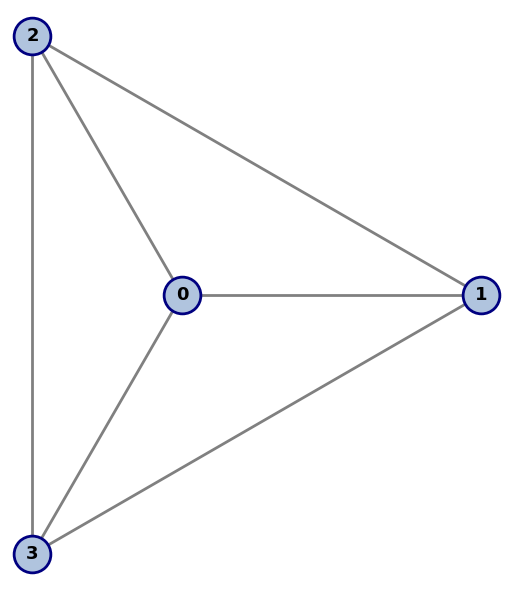

In [21]:
graph = graph_1
pos = tutte_embedding(graph)

draw_embedding(graph, pos)

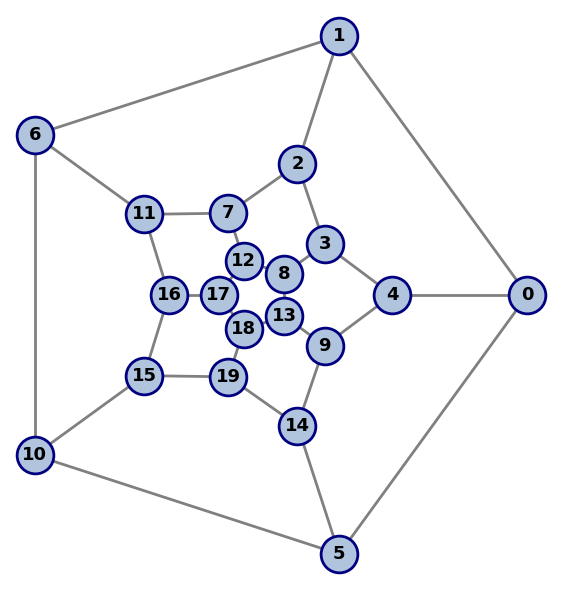

In [22]:
graph = graph_2
pos = tutte_embedding(graph)

draw_embedding(graph, pos)

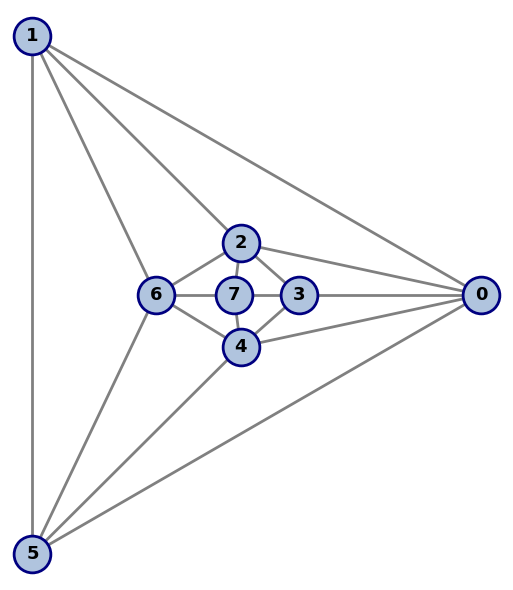

In [23]:
graph = graph_3
pos = tutte_embedding(graph)

draw_embedding(graph, pos)

Граф не 3-связный


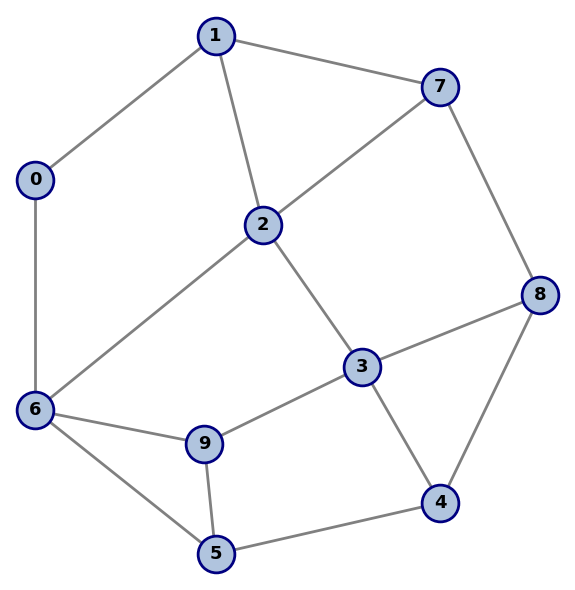

In [24]:
graph = graph_8
pos = tutte_embedding(graph)

draw_embedding(graph, pos)